In [1]:
!pip -q install lightgbm

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.signal import find_peaks
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from google.colab import drive

drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/Хакатон Газпром"
RAW_PATH = os.path.join(DATA_DIR, "hakhathon_data.csv")
FEAT_PATH = os.path.join(DATA_DIR, "features_v1.parquet")  # опционально

df = pd.read_csv(RAW_PATH)
df["Time"] = pd.to_datetime(df["Time"], format="%d.%m.%Y %H:%M:%S")
df = df.sort_values("ID").reset_index(drop=True)
N = len(df)

dt = df["Time"].diff().dt.total_seconds().fillna(5.0).to_numpy()
gaps = np.where(dt > 10.0)[0]
print(f"Данные загружены: {df.shape}, разрывов >10 сек: {len(gaps)}")

# Центрированная скорость (строго внутри непрерывных кусков без разрывов)
def get_centered_slope(arr, half_w, dt_arr, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(arr)]
    res = np.zeros(len(arr), dtype=np.float32)
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = arr[a:b]
        n = len(seg)
        if n <= 2:
            continue
        idx = np.arange(n)
        lo = np.maximum(0, idx - half_w)
        hi = np.minimum(n - 1, idx + half_w)
        res[a:b] = (seg[hi] - seg[lo]) / np.maximum(hi - lo, 1)
    return res

# Центрированное скользящее std без перескока через разрывы (для LightGBM)
def get_rolling_std(arr, win, dt_arr, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(arr)]
    res = np.zeros(len(arr), dtype=np.float32)
    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a <= 2:
            continue
        res[a:b] = pd.Series(arr[a:b]).rolling(win, min_periods=1, center=True).std().fillna(0.0).to_numpy(dtype=np.float32)
    return res

# Усреднение вероятностей внутри атомарных отрезков между скачками
def pool_by_segments(proba, bounds):
    out = np.empty_like(proba)
    for k in range(len(bounds) - 1):
        a, b = bounds[k], bounds[k + 1]
        out[a:b] = proba[a:b].mean(axis=0, keepdims=True)
    return out

# Выравнивание номеров кластеров под эталонную разметку (венгерский алгоритм)
def align_proba(proba, ref_labels):
    pred = np.argmax(proba, axis=1)
    cm = np.zeros((9, 9), dtype=np.int64)
    np.add.at(cm, (ref_labels, pred), 1)
    rows, cols = linear_sum_assignment(-cm)
    out = np.zeros_like(proba)
    for r, c in zip(rows, cols):
        out[:, r] = proba[:, c]
    return out

# Сглаживание Витерби строго внутри непрерывных интервалов
def viterbi_smooth(proba, stay_bonus=15.0):
    T, K = proba.shape
    log_p = np.log(np.clip(proba, 1e-9, 1.0))
    dp = np.zeros((T, K), dtype=np.float64)
    back = np.zeros((T, K), dtype=np.int32)
    dp[0] = log_p[0]
    for t in range(1, T):
        prev = dp[t - 1]
        best_i = int(np.argmax(prev))
        best_v = prev[best_i]
        stay_v = prev + stay_bonus
        keep = stay_v >= best_v
        dp[t] = log_p[t] + np.where(keep, stay_v, best_v)
        back[t] = np.where(keep, np.arange(K), best_i)
    path = np.zeros(T, dtype=np.int8)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 2, -1, -1):
        path[t] = back[t + 1, path[t + 1]]
    return path

def viterbi_gap_aware(proba, dt_arr, stay_bonus=15.0, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(proba)]
    out = np.empty(len(proba), dtype=np.int8)
    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a <= 2:
            out[a:b] = np.argmax(proba[a:b], axis=1)
        else:
            out[a:b] = viterbi_smooth(proba[a:b], stay_bonus=stay_bonus)
    return out

# Чистка совсем коротких выбросов (1-2 строки)
def clean_short_segments(labels, dt_arr, min_len=3, gap_thr=10.0):
    cuts = np.where(dt_arr > gap_thr)[0]
    bounds = np.r_[0, cuts, len(labels)]
    out = labels.copy()
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = out[a:b].copy()
        if len(seg) <= min_len:
            continue
        while True:
            ch = np.where(np.diff(seg) != 0)[0] + 1
            st, en = np.r_[0, ch], np.r_[ch, len(seg)]
            ln = en - st
            short = np.where(ln < min_len)[0]
            if len(short) == 0 or len(ln) <= 1:
                break
            idx = int(short[np.argmin(ln[short])])
            s0, s1 = st[idx], en[idx]
            if idx == 0:
                seg[s0:s1] = seg[en[0]]
            elif idx == len(ln) - 1:
                seg[s0:s1] = seg[st[idx] - 1]
            else:
                seg[s0:s1] = seg[s0 - 1] if ln[idx - 1] >= ln[idx + 1] else seg[s1]
        out[a:b] = seg
    return out

Mounted at /content/drive
Данные загружены: (180901, 12), разрывов >10 сек: 17


In [2]:
# 1. Чистим отрицательные глюки датчиков
bp    = np.clip(df["BitPosition"].to_numpy(dtype=np.float32), 0.0, None)
rop   = np.clip(df["ROP"].to_numpy(dtype=np.float32), 0.0, None)
flow  = np.clip(df["InletFlow"].to_numpy(dtype=np.float32), 0.0, None)
pres  = np.clip(df["ManifoldPressure"].to_numpy(dtype=np.float32), 0.0, None)
rot   = np.clip(df["Turn_rotor"].to_numpy(dtype=np.float32), 0.0, None)
wedge = np.clip(df["WedgePosition"].to_numpy(dtype=np.float32), 0.0, 1.5)
hl    = np.clip(df["HL"].to_numpy(dtype=np.float32), 0.0, None)
load  = np.clip(df["Load"].to_numpy(dtype=np.float32), 0.0, None)
blk   = np.clip(df["TravelingBlockPosition"].to_numpy(dtype=np.float32), 0.0, None)
depth = df["Depth"].to_numpy(dtype=np.float32)

# Размах блока за 30 сек (из features_v1 Никиты, если файл есть, иначе считаем сами)
if os.path.exists(FEAT_PATH):
    feat_nik = pd.read_parquet(FEAT_PATH).sort_values("ID").reset_index(drop=True)
    blk_range = feat_nik["block_range_30s"].astype(np.float32).fillna(0.0).clip(0.0, 30.0).to_numpy()
else:
    s_blk = df["TravelingBlockPosition"]
    blk_range = (s_blk.rolling(6, min_periods=1).max() - s_blk.rolling(6, min_periods=1).min()).fillna(0.0).clip(0.0, 30.0).to_numpy(dtype=np.float32)

# 2. Базовая матрица из 13 признаков
feat_df = pd.DataFrame({
    "BitPosition": bp, "ROP": rop, "InletFlow": flow, "ManifoldPressure": pres,
    "Turn_rotor": rot, "WedgePosition": wedge, "HL": hl, "Load": load,
    "flow_on": (flow > 1.5).astype(np.float32),
    "on_bottom": (bp < 2.0).astype(np.float32),
    "bit_slope": np.clip(get_centered_slope(bp, 12, dt), -5.0, 5.0),
    "depth_slope": np.clip(get_centered_slope(depth, 12, dt), -0.2, 1.0),
    "block_range_30s": blk_range,
})

weights = np.array([1.0, 1.1, 1.1, 0.9, 1.1, 1.35, 1.0, 1.0, 0.8, 0.8, 1.0, 1.0, 0.6], dtype=np.float32)
X_base = np.clip(StandardScaler().fit_transform(feat_df.to_numpy()), -6.0, 6.0).astype(np.float32) * weights

# 3. Атомарные границы по скачкам 8 датчиков (с подавлением «зебры» внутри быстрого СПО)
X_inst = np.clip(StandardScaler().fit_transform(feat_df.iloc[:, :8].to_numpy()), -6.0, 6.0)
jump = np.zeros(N, dtype=np.float32)
jump[1:] = np.linalg.norm(X_inst[1:] - X_inst[:-1], axis=1)

bit_slope_w20 = np.clip(get_centered_slope(bp, 20, dt), -5.0, 5.0)
active_tripping = (flow < 1.0) & (np.abs(bit_slope_w20) > 0.65)
jump_clean = jump.copy()
jump_clean[active_tripping] *= 0.20

thr = float(np.percentile(jump, 97.0))
peaks, _ = find_peaks(jump_clean, height=thr, distance=5)
trip_edges = np.where(np.diff(active_tripping.astype(np.int8)) != 0)[0] + 1
cp_bounds = np.unique(np.r_[0, peaks, trip_edges, gaps, N])

# 4. Базовая модель 1 (v15, 5-seed KMeans) — нужна как эталон нумерации классов и для якорей
probas_5, preds_5 = [], []
for s in [0, 21, 42, 123, 777]:
    km = KMeans(n_clusters=9, n_init=15, max_iter=400, random_state=s).fit(X_base[::3])
    d2 = np.stack([np.sum((X_base - c) ** 2, axis=1) for c in km.cluster_centers_], axis=1)
    ex = np.exp(np.clip(-(d2 - d2.min(axis=1, keepdims=True)) / 3.0, -30.0, 0.0))
    pr = (ex / ex.sum(axis=1, keepdims=True)).astype(np.float32)
    probas_5.append(pr)
    preds_5.append(np.argmax(pr, axis=1))

ref_pred = preds_5[2]
proba_5seed = np.mean([align_proba(pr, ref_pred) for pr in probas_5], axis=0).astype(np.float32)
proba_v15_atomic = pool_by_segments(proba_5seed, cp_bounds)
pred_v15 = clean_short_segments(viterbi_gap_aware(proba_v15_atomic, dt, stay_bonus=15.0), dt, min_len=3)

print(f"Общая база готова | отрезков CPD: {len(cp_bounds) - 1} | сегментов v15: {int(np.sum(np.diff(pred_v15) != 0) + 1)}")

Общая база готова | отрезков CPD: 3663 | сегментов v15: 988


2 вариант

In [3]:
# 1. Собираем 24 контекстных признака (датчики + флаги + 2 масштаба скоростей + волатильность)
ctx_df = pd.DataFrame({
    "BitPosition": bp, "ROP": rop, "InletFlow": flow, "ManifoldPressure": pres,
    "Turn_rotor": rot, "WedgePosition": wedge, "HL": hl, "Load": load,
    "flow_on":      (flow > 1.5).astype(np.float32),
    "on_bottom":    (bp < 2.0).astype(np.float32),
    "wedge_closed": (wedge < 0.3).astype(np.float32),
    "high_load":    (load > 20.0).astype(np.float32),
    "bit_sl_6":     np.clip(get_centered_slope(bp, 6, dt), -8.0, 8.0),
    "bit_sl_20":    np.clip(get_centered_slope(bp, 20, dt), -5.0, 5.0),
    "dep_sl_6":     np.clip(get_centered_slope(depth, 6, dt), -0.2, 1.5),
    "dep_sl_20":    np.clip(get_centered_slope(depth, 20, dt), -0.2, 1.0),
    "hl_sl_6":      np.clip(get_centered_slope(hl, 6, dt), -15.0, 15.0),
    "blk_std_11":   get_rolling_std(blk, 11, dt),
    "blk_std_31":   get_rolling_std(blk, 31, dt),
    "hl_std_11":    get_rolling_std(hl, 11, dt),
    "hl_std_31":    get_rolling_std(hl, 31, dt),
    "flow_std_11":  get_rolling_std(flow, 11, dt),
    "rot_std_11":   get_rolling_std(rot, 11, dt),
    "blk_rng30":    blk_range,
})
X_ctx = ctx_df.to_numpy(dtype=np.float32)

# 2. Выбираем чистые «якоря»: середина сегментов v15 (отступ 3 шага от краёв) с уверенностью >= 0.70
ch = np.where(np.diff(pred_v15) != 0)[0] + 1
st, en = np.r_[0, ch], np.r_[ch, N]
interior_mask = np.zeros(N, dtype=bool)
for a, b in zip(st, en):
    if b - a >= 12:
        interior_mask[a + 3 : b - 3] = True

conf_mask = proba_5seed.max(axis=1) >= 0.70

rng = np.random.default_rng(42)
anchor_idx = []
for cls in range(9):
    pool = np.where((pred_v15 == cls) & interior_mask & conf_mask)[0]
    if len(pool) < 200:
        pool = np.where(pred_v15 == cls)[0]
    take = min(len(pool), 4500)
    anchor_idx.append(rng.choice(pool, size=take, replace=False))
anchor_idx = np.concatenate(anchor_idx)

# 3. Обучаем LightGBM с балансировкой классов (помогает редким операциям и Macro F1)
lgb_model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=9,
    n_estimators=260,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=40,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)
lgb_model.fit(X_ctx[anchor_idx], pred_v15[anchor_idx])

# 4. Получаем вероятности на всём ряде, пулим по скачкам и сглаживаем
proba_lgb_raw = np.clip(lgb_model.predict_proba(X_ctx), 1e-6, 1.0).astype(np.float32)
proba_v2_lgb = pool_by_segments(proba_lgb_raw, cp_bounds)
pred_v2_lgb = clean_short_segments(viterbi_gap_aware(proba_v2_lgb, dt, stay_bonus=15.0), dt, min_len=3)

# Топ-6 важных признаков для понимания, на что опирается бустинг
top_imp = pd.Series(lgb_model.feature_importances_, index=ctx_df.columns).sort_values(ascending=False)
print(f"Вариант 2 (LightGBM) готов | якорей: {len(anchor_idx)} | сегментов: {int(np.sum(np.diff(pred_v2_lgb) != 0) + 1)}")
print("Топ-6 фичей LightGBM:", top_imp.head(6).to_dict())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Вариант 2 (LightGBM) готов | якорей: 39536 | сегментов: 831
Топ-6 фичей LightGBM: {'BitPosition': 8730, 'bit_sl_20': 5617, 'Turn_rotor': 4806, 'hl_std_31': 4464, 'blk_std_31': 4394, 'rot_std_11': 4354}


3 вариант

In [4]:
# Учим GMM на каждой 3-й точке (быстро и стабильно), затем предсказываем вероятности на всех строках
gmm = GaussianMixture(
    n_components=9,
    covariance_type="tied",
    reg_covar=1e-2,
    n_init=5,
    max_iter=300,
    random_state=42,
)
gmm.fit(X_base[::3])

proba_gmm_raw = np.clip(gmm.predict_proba(X_base), 1e-6, 1.0).astype(np.float32)

# Выравниваем номера классов GMM под v15, чтобы все 3 модели говорили на одном языке
proba_gmm_aligned = align_proba(proba_gmm_raw, pred_v15)

# Пулим по границам скачков и сглаживаем Витерби
proba_v3_gmm = pool_by_segments(proba_gmm_aligned, cp_bounds)
pred_v3_gmm = clean_short_segments(viterbi_gap_aware(proba_v3_gmm, dt, stay_bonus=15.0), dt, min_len=3)

print(f"Вариант 3 (GMM tied) готов | сегментов: {int(np.sum(np.diff(pred_v3_gmm) != 0) + 1)}")

Вариант 3 (GMM tied) готов | сегментов: 1252


Сравнение 3х вариантов

,Model,Segments,Short<=2,MinClass%,ARI_vs_v15
0,Вариант 1: v15_kmeans_cpd,988,0,2.86,1.0000
1,Вариант 2: v16_lgb_ctx,831,0,3.09,0.9561
2,Вариант 3: gmm_tied_cpd,1252,0,5.28,0.7783


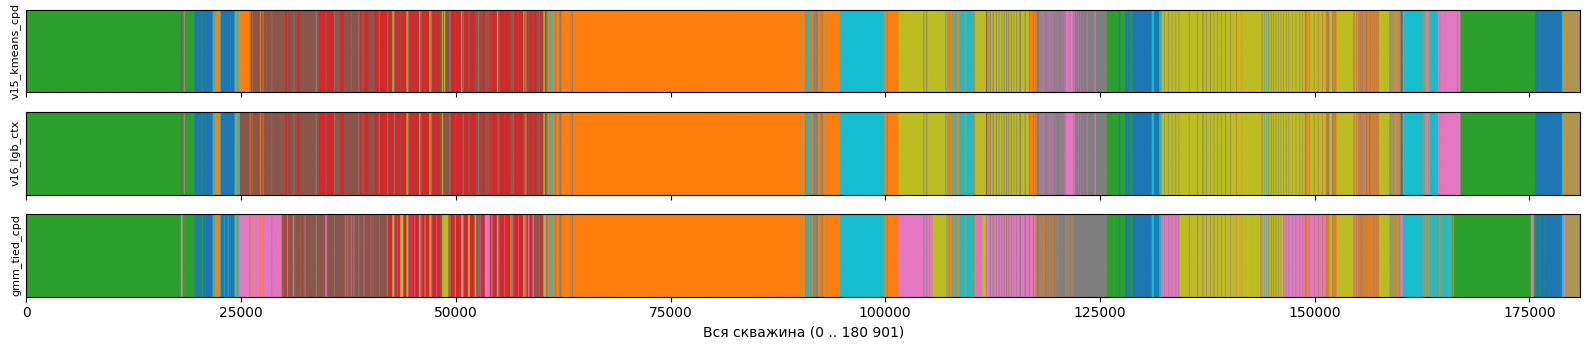

In [5]:
models = [
    ("Вариант 1: v15_kmeans_cpd", pred_v15),
    ("Вариант 2: v16_lgb_ctx",    pred_v2_lgb),
    ("Вариант 3: gmm_tied_cpd",   pred_v3_gmm),
]

rows = []
for name, arr in models:
    ch = np.where(np.diff(arr) != 0)[0] + 1
    lens = np.diff(np.r_[0, ch, N])
    min_share = float(pd.Series(arr).value_counts().min() / N * 100.0)
    rows.append({
        "Model": name,
        "Segments": int(len(lens)),
        "Short<=2": int((lens <= 2).sum()),
        "MinClass%": round(min_share, 2),
        "ARI_vs_v15": round(adjusted_rand_score(pred_v15, arr), 4),
    })
display(pd.DataFrame(rows))

# Визуальное сравнение всей скважины
fig, axes = plt.subplots(3, 1, figsize=(16, 3.6), sharex=True)
for ax, (name, arr) in zip(axes, models):
    ax.imshow(arr[::10][None, :], aspect="auto", cmap="tab10", vmin=0, vmax=8, extent=[0, N, 0, 1])
    ax.set_ylabel(name.split(":")[1].strip(), fontsize=8)
    ax.set_yticks([])
plt.xlabel("Вся скважина (0 .. 180 901)")
plt.tight_layout()
plt.show()

In [6]:
OUT_DIR = os.path.join(DATA_DIR, "for_danya_ensemble")
os.makedirs(OUT_DIR, exist_ok=True)

to_save = [
    ("yulia_v16_lgb_ctx",  pred_v2_lgb, proba_v2_lgb),
    ("yulia_gmm_tied_cpd", pred_v3_gmm, proba_v3_gmm),
]

for tag, pred, proba in to_save:
    assert pred.shape == (N,) and proba.shape == (N, 9), f"Неверная форма у {tag}"
    assert not np.isnan(proba).any(), f"Есть NaN в вероятностях {tag}"
    assert sorted(np.unique(pred).tolist()) == list(range(9)), f"Не все 9 классов у {tag}"

    p_pred = os.path.join(OUT_DIR, f"pred_{tag}.npy")
    p_prob = os.path.join(OUT_DIR, f"proba_{tag}.npy")
    np.save(p_pred, pred.astype(np.int8))
    np.save(p_prob, proba.astype(np.float16))
    print(f"Сохранено: {p_pred} и {p_prob}")

Сохранено: /content/drive/MyDrive/Хакатон Газпром/for_danya_ensemble/pred_yulia_v16_lgb_ctx.npy и /content/drive/MyDrive/Хакатон Газпром/for_danya_ensemble/proba_yulia_v16_lgb_ctx.npy
Сохранено: /content/drive/MyDrive/Хакатон Газпром/for_danya_ensemble/pred_yulia_gmm_tied_cpd.npy и /content/drive/MyDrive/Хакатон Газпром/for_danya_ensemble/proba_yulia_gmm_tied_cpd.npy
